# **Proyecto 1 - Etapa 2**

## **Importaciones**

In [1]:
import re
import unicodedata

import matplotlib.pyplot as plt
import nltk
import pandas as pd
from nltk import PorterStemmer
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords')
nltk.download('wordnet')
stop_words = stopwords.words('spanish')
wpt = nltk.WordPunctTokenizer()
ps = PorterStemmer()
import re
import unicodedata
from collections import Counter

import nltk
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Juan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Juan\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## **Sección 1 Aumentación de datos y reentrenamiento del modelo**

Se importan los datos los datos de la etapa 1 y 2.

In [2]:
original_data = pd.read_excel('data/Datos_proyecto.xlsx')
original_data_2 = pd.read_excel('data/Datos_etapa 2.xlsx')

print("Dimensiones primer conjunto de datos:", original_data.shape, "\n")
print("Dimensiones segundo conjunto de datos:", original_data_2.shape, "\n")

print("Tipos de datos por columna:")
print(original_data.dtypes)
print(original_data_2.dtypes)

display(original_data.head())
display(original_data_2.head())

print("\nValores únicos por columna:")
print(original_data.nunique())
print(original_data_2.nunique())

Dimensiones primer conjunto de datos: (2424, 2) 

Dimensiones segundo conjunto de datos: (99, 2) 

Tipos de datos por columna:
textos    object
labels     int64
dtype: object
textos    object
labels     int64
dtype: object


,textos,labels
0,"""Aprendizaje"" y ""educación"" se consideran sinó...",4
1,Para los niños más pequeños (bebés y niños peq...,4
2,"Además, la formación de especialistas en medic...",3
3,En los países de la OCDE se tiende a pasar de ...,4
4,Este grupo se centró en las personas que padec...,3


,textos,labels
0,La definición de privación está basada en el m...,1
1,La mayoría de los programas de protección soci...,1
2,Esto es dos veces y media mayor que la partici...,1
3,El enfoque aquí está en los aspectos de la pob...,1
4,El factor educativo representa una mayor contr...,1



Valores únicos por columna:
textos    2424
labels       3
dtype: int64
textos    99
labels     3
dtype: int64


### **Perfilamiento de los Datos**

Para el perfilamiento de datos, se veran las distribuciones de solo el segundo conjunto de datos.

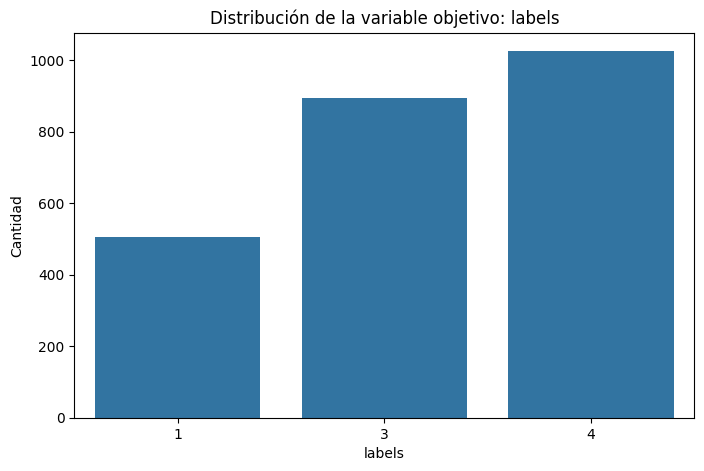

labels
4    43
3    35
1    21
Name: count, dtype: int64


In [3]:
plt.figure(figsize=(8, 5))
sns.countplot(data=original_data, x='labels')
plt.title('Distribución de la variable objetivo: labels')
plt.ylabel('Cantidad')
plt.show()

label_counts = original_data_2['labels'].value_counts()
print(label_counts)

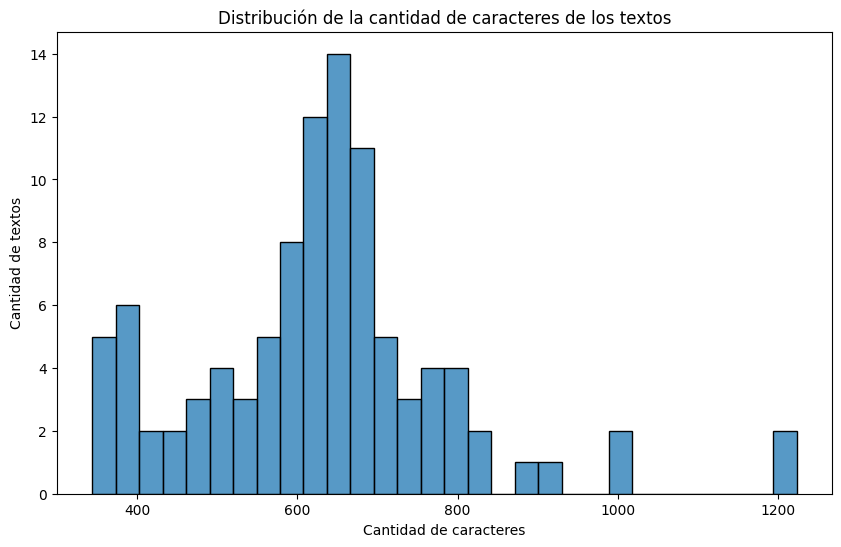

Estadísticas descriptivas de la cantidad de caracteres de los textos:
count      99.000000
mean      629.595960
std       162.232192
min       344.000000
25%       543.000000
50%       634.000000
75%       692.000000
max      1223.000000
Name: textos, dtype: float64


In [4]:
text_character_counts = original_data_2['textos'].str.len()
plt.figure(figsize=(10, 6))
sns.histplot(text_character_counts, bins=30)
plt.title('Distribución de la cantidad de caracteres de los textos')
plt.xlabel('Cantidad de caracteres')
plt.ylabel('Cantidad de textos')
plt.show()

print("Estadísticas descriptivas de la cantidad de caracteres de los textos:")
print(text_character_counts.describe())

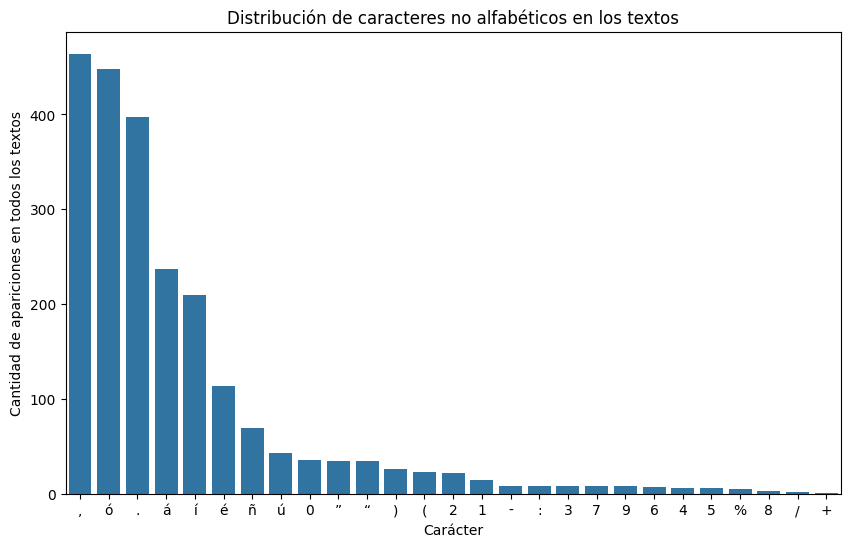

   character  count
3          ,    464
0          ó    448
4          .    397
1          á    237
12         í    210
22         é    114
2          ñ     69
17         ú     43
16         0     36
21         ”     35
20         “     35
9          )     26
5          (     23
7          2     22
18         1     14
23         -      8
24         :      8
14         3      8
11         7      8
19         9      8
10         6      7
13         4      6
6          5      6
8          %      5
15         8      3
25         /      2
26         +      1
Estadísticas descriptivas de la cantidad de caracteres no alfabéticos:
count     27.000000
mean      83.074074
std      140.501828
min        1.000000
25%        7.500000
50%       22.000000
75%       56.000000
max      464.000000
Name: count, dtype: float64


In [5]:
text_non_alpha_chars = original_data_2['textos'].str.lower().str.findall(r'[^a-zA-Z\s]', flags=re.UNICODE)
all_non_alpha_chars = [char for sublist in text_non_alpha_chars for char in sublist]
non_alpha_char_counts = Counter(all_non_alpha_chars)

non_alpha_char_counts_df = pd.DataFrame(non_alpha_char_counts.items(), columns=['character', 'count']).sort_values(by='count', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=non_alpha_char_counts_df, x='character', y='count')
plt.title('Distribución de caracteres no alfabéticos en los textos')
plt.xlabel('Carácter')
plt.ylabel('Cantidad de apariciones en todos los textos')
plt.show()

print(non_alpha_char_counts_df)

print("Estadísticas descriptivas de la cantidad de caracteres no alfabéticos:")
print(non_alpha_char_counts_df['count'].describe())

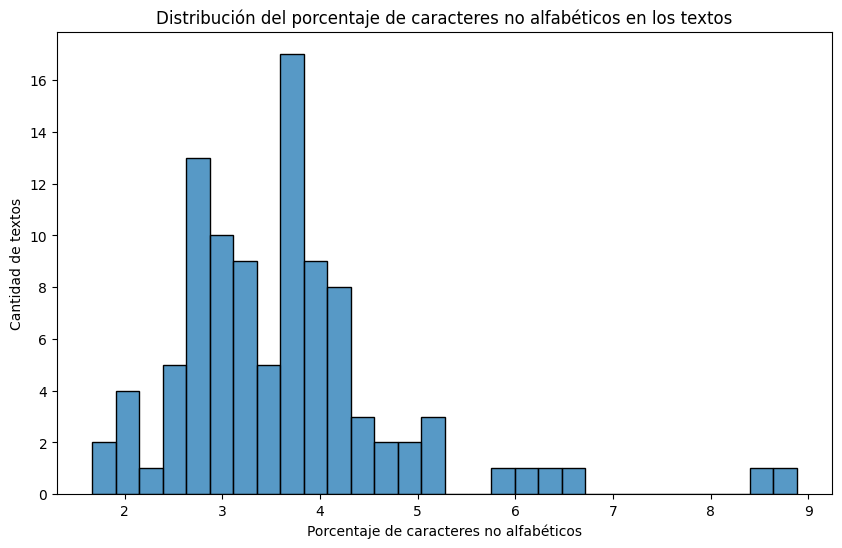

,special_char_percentage
35,8.882521
8,8.433735
4,6.686047
6,6.366048
0,6.218487
39,5.978261
76,5.154639
74,5.145798
9,5.088063
38,4.932735


Estadísticas descriptivas del porcentaje de caracteres no alfabéticos por texto:
count    99.000000
mean      3.645546
std       1.187829
min       1.666667
25%       2.869204
50%       3.593750
75%       4.046262
max       8.882521
Name: special_char_percentage, dtype: float64


In [6]:
special_char_percentages = [(len(na_chars)/total)*100 for na_chars, total in zip(text_non_alpha_chars, text_character_counts)]

special_char_percentages_df = pd.DataFrame({
    'special_char_percentage': special_char_percentages
})

plt.figure(figsize=(10, 6))
sns.histplot(special_char_percentages_df['special_char_percentage'], bins=30)
plt.title('Distribución del porcentaje de caracteres no alfabéticos en los textos')
plt.xlabel('Porcentaje de caracteres no alfabéticos')
plt.ylabel('Cantidad de textos')
plt.show()

special_char_percentages_df.sort_values(by='special_char_percentage', ascending=False, inplace=True)
display(special_char_percentages_df.head(15))

print("Estadísticas descriptivas del porcentaje de caracteres no alfabéticos por texto:")
print(special_char_percentages_df['special_char_percentage'].describe())

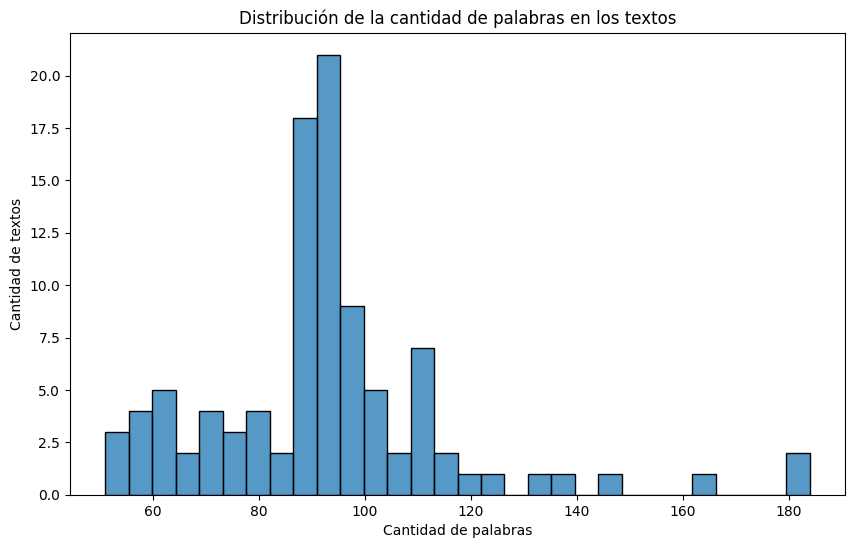

Estadísticas descriptivas de la cantidad de palabras en los textos:
count     99.000000
mean      92.373737
std       23.260102
min       51.000000
25%       83.000000
50%       91.000000
75%       98.500000
max      184.000000
Name: textos, dtype: float64


In [7]:
text_word_counts = original_data_2['textos'].str.split().str.len()
plt.figure(figsize=(10, 6))
sns.histplot(text_word_counts, bins=30)
plt.title('Distribución de la cantidad de palabras en los textos')
plt.xlabel('Cantidad de palabras')
plt.ylabel('Cantidad de textos')
plt.show()

print("Estadísticas descriptivas de la cantidad de palabras en los textos:")
print(text_word_counts.describe())

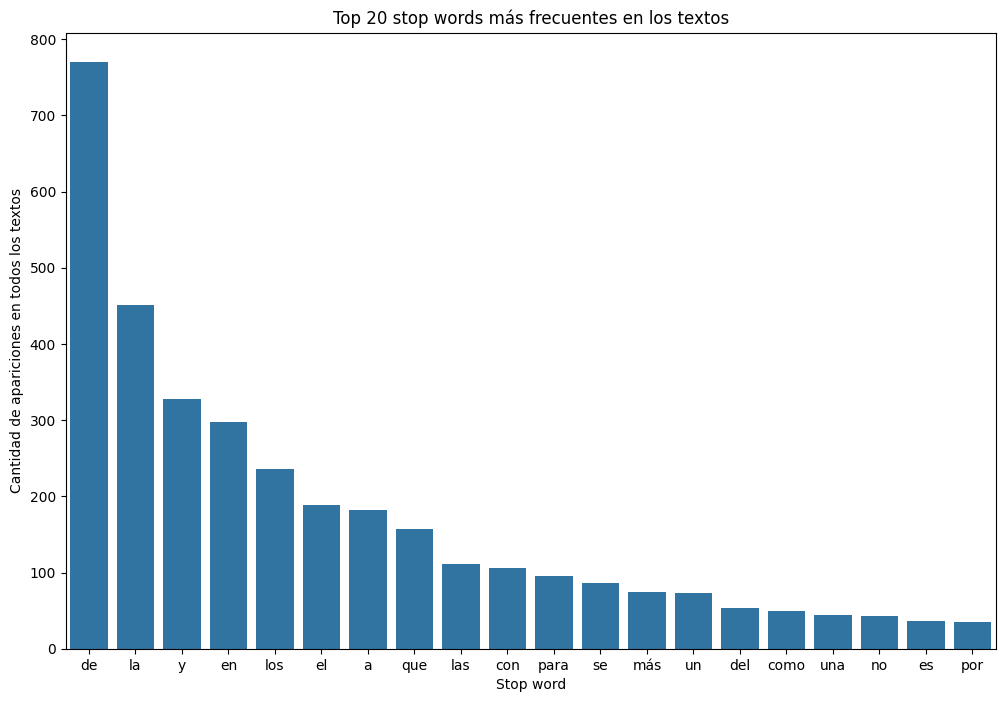

    stop_word  count
0          de    770
1          la    451
5           y    328
4          en    298
7         los    236
..        ...    ...
308    tenido      0
309    tenida      0
310   tenidos      0
311   tenidas      0
288  teníamos      0

[313 rows x 2 columns]
Estadísticas descriptivas de la cantidad de apariciones de stop words:
count    313.000000
mean      12.370607
std       61.034380
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max      770.000000
Name: count, dtype: float64


In [8]:
stop_word_counts = {word: original_data_2['textos'].str.count(rf'\b{re.escape(word)}\b', flags=re.IGNORECASE).sum() for word in stop_words}
stop_word_counts_df = pd.DataFrame(list(stop_word_counts.items()), columns=['stop_word', 'count']).sort_values(by='count', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(data=stop_word_counts_df.head(20), x='stop_word', y='count')
plt.title('Top 20 stop words más frecuentes en los textos')
plt.xlabel('Stop word')
plt.ylabel('Cantidad de apariciones en todos los textos')
plt.show()

print(stop_word_counts_df)

print("Estadísticas descriptivas de la cantidad de apariciones de stop words:")
print(stop_word_counts_df['count'].describe())

### **Análisis de Calidad de Datos**

#### **Completitud**

In [9]:
print("Valores nulos por columna:")
print(original_data_2.isnull().sum())

Valores nulos por columna:
textos    0
labels    0
dtype: int64


#### **Unicidad**

In [10]:
print("Cantidad de textos duplicados:")
print(original_data_2['textos'].duplicated().sum())

Cantidad de textos duplicados:
0


#### **Validez**

In [11]:
print("Conteo de valores de labels:")
print(original_data_2['labels'].value_counts())

Conteo de valores de labels:
labels
4    43
3    35
1    21
Name: count, dtype: int64


In [12]:
original_data['textos'] = original_data['textos'].astype('string')
original_data_2['textos'] = original_data_2['textos'].astype('string')

In [13]:
print("Tipos de datos por columna:")
print(original_data.dtypes)
print(original_data_2.dtypes)

Tipos de datos por columna:
textos    string[python]
labels             int64
dtype: object
textos    string[python]
labels             int64
dtype: object


### **Preparación de conjunto de datos etapa 1 y etapa 2**

In [14]:
nltk.download('punkt')
nltk.download('punkt_tab')

# Funciones de reemplazo
def replace_accents(text: str) -> str:
    normalized = unicodedata.normalize('NFD', text)
    without_accents = ''.join(c for c in normalized if unicodedata.category(c) != 'Mn')
    return without_accents

def replace_numbers_with_text(text: str) -> str:
    num_map = {
        '0': 'cero',
        '1': 'uno',
        '2': 'dos',
        '3': 'tres',
        '4': 'cuatro',
        '5': 'cinco',
        '6': 'seis',
        '7': 'siete',
        '8': 'ocho',
        '9': 'nueve'
    }
    return re.sub(r'\d', lambda m: num_map[m.group()], text)

# Normalización, tokenización y stemming
stemmer = SnowballStemmer("spanish")
spanish_stopwords = set(stopwords.words("spanish"))

def basic_normalize(text: str) -> str:
    """lowercase, reemplazar acentos, reemplazar números, eliminar caracteres especiales"""
    if text is None:
        return ""
    text = str(text).lower().strip()
    text = replace_accents(text)
    text = replace_numbers_with_text(text)
    # dejar solo letras a-z y espacios
    text = re.sub(r'[^a-z\s]', ' ', text, flags=re.UNICODE)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def tokenize_text(text: str) -> list[str]:
    """Tokenizar usando word_tokenize (nltk.tokenize)"""
    if not text:
        return []
    return word_tokenize(text, language='spanish')

def stem_tokens(tokens: list[str], remove_sw: bool = True) -> list[str]:
    """Aplica SnowballStemmer a la lista de tokens. Opcionalmente quita stopwords."""
    if remove_sw:
        tokens = [t for t in tokens if t not in spanish_stopwords]
    return [stemmer.stem(t) for t in tokens if t.strip()]

def process_text_once(text: str, remove_stopwords: bool = True) -> str:
    """Pipeline por texto: normalize -> tokenize -> optional remove stopwords -> stem -> join."""
    basic = basic_normalize(text)
    toks = tokenize_text(basic)
    stems = stem_tokens(toks, remove_sw=remove_stopwords)
    return " ".join(stems)

def normalize_texts_nltk(series: pd.Series, remove_stopwords: bool = False) -> pd.Series:
    """Aplica process_text_once a una pd.Series de textos."""
    series = series.fillna("").astype(str)
    return series.apply(lambda s: process_text_once(s, remove_stopwords=remove_stopwords))

# Se crea una copia del DataFrame original para no modificarlo
df = original_data.copy()
df_2 = original_data_2.copy()

# Preprocesamiento de textos, se omite porque se hará en el pipeline (dejamos comentado para referencia)
#df['text_processed'] = normalize_texts_nltk(df['textos'], remove_stopwords=True)
#df_2['text_processed'] = normalize_texts_nltk(df_2['textos'], remove_stopwords=True)

X = df['textos']
y = df['labels']

X_2 = df_2['textos']
y_2 = df_2['labels']

TEST_SIZE = 0.20    # porcentaje final para test
RANDOM_STATE = 42

# Series de entrada
X = df['textos'].astype(str)
y = df['labels'].values

X_2 = df_2['textos'].astype(str)
y_2 = df_2['labels'].values

# Proporciones originales de las clases
print("Distribución original (proporciones):")
print(pd.Series(y).value_counts(normalize=True).sort_index())
print("Distribución original segundo conjunto de datos (proporciones):")
print(pd.Series(y_2).value_counts(normalize=True).sort_index())

# 1) Primer split: sacar TEST (manteniendo stratify si es posible)
try:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
    )
    X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
        X_2, y_2, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_2
    )
except ValueError as e:
    print("WARNING: stratify falló en la separación test (posible clase con muy pocas muestras).")
    print("Detalle:", e)
    print("Procediendo con split no estratificado para test.")
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=None
    )
    X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
        X_2, y_2, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=None
    )


# Resumen de tamaños y proporciones
print("\nTamaños (nº muestras):")
print("Total:", len(X))
print("Train primer conjunto:", len(X_train))

print("Test primer conjunto:", len(X_test))
print("Train segundo conjunto:", len(X_train_2))
print("Test segundo conjunto:", len(X_test_2))

print("\nDistribuciones por conjunto (proporciones):")
print("Train primer conjunto:")
print(pd.Series(y_train).value_counts(normalize=True).sort_index())

print("Test primer conjunto:")
print(pd.Series(y_test).value_counts(normalize=True).sort_index())
print("Train segundo conjunto:")
print(pd.Series(y_train_2).value_counts(normalize=True).sort_index())
print("Test segundo conjunto:")
print(pd.Series(y_test_2).value_counts(normalize=True).sort_index())

Distribución original (proporciones):
1    0.208333
3    0.368812
4    0.422855
Name: proportion, dtype: float64
Distribución original segundo conjunto de datos (proporciones):
1    0.212121
3    0.353535
4    0.434343
Name: proportion, dtype: float64

Tamaños (nº muestras):
Total: 2424
Train primer conjunto: 1939
Test primer conjunto: 485
Train segundo conjunto: 79
Test segundo conjunto: 20

Distribuciones por conjunto (proporciones):
Train primer conjunto:
1    0.208355
3    0.368747
4    0.422898
Name: proportion, dtype: float64
Test primer conjunto:
1    0.208247
3    0.369072
4    0.422680
Name: proportion, dtype: float64
Train segundo conjunto:
1    0.21519
3    0.35443
4    0.43038
Name: proportion, dtype: float64
Test segundo conjunto:
1    0.20
3    0.35
4    0.45
Name: proportion, dtype: float64


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Juan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Juan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Para que el mismo pipeline se encargue de la normalización, lo cual será de utilidad al momento de exportarlo, crearemos un transformer con las funciones NLTK correspondientes.

In [15]:

from sklearn.base import BaseEstimator, TransformerMixin
import pandas as pd

class TextNormalizer(BaseEstimator, TransformerMixin):
    def __init__(self, remove_stopwords=True):
        self.remove_stopwords = remove_stopwords

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        s = pd.Series(X).fillna("").astype(str)
        return s.apply(lambda t: process_text_once(t, remove_stopwords=self.remove_stopwords))


Las distribuciones finales se muestran a continuación

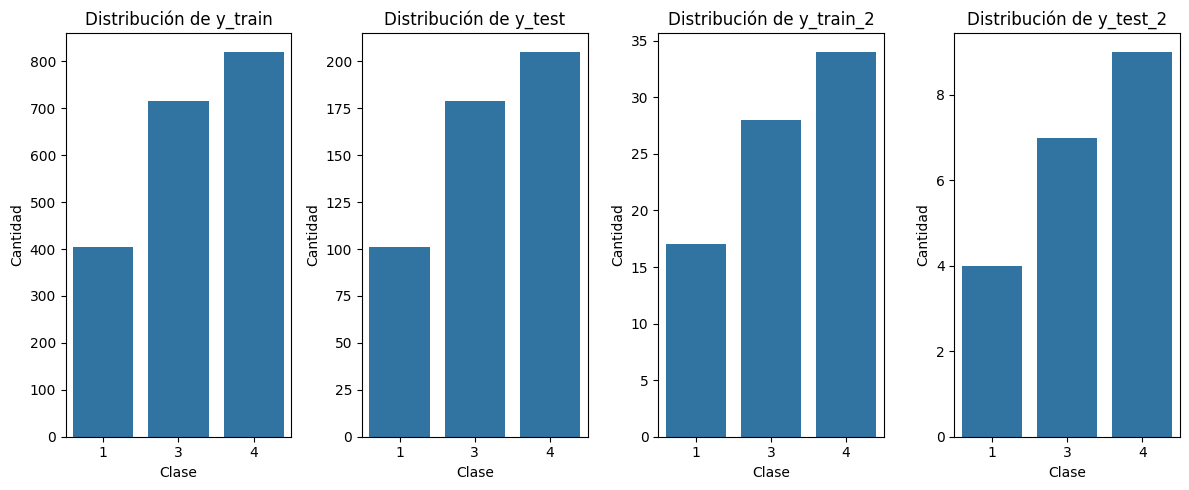

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(12, 5))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title('Distribución de y_train')
axes[0].set_xlabel('Clase')
axes[0].set_ylabel('Cantidad')

sns.countplot(x=y_test, ax=axes[1])
axes[1].set_title('Distribución de y_test')
axes[1].set_xlabel('Clase')
axes[1].set_ylabel('Cantidad')

sns.countplot(x=y_train_2, ax=axes[2])
axes[2].set_title('Distribución de y_train_2')
axes[2].set_xlabel('Clase')
axes[2].set_ylabel('Cantidad')

sns.countplot(x=y_test_2, ax=axes[3])
axes[3].set_title('Distribución de y_test_2')
axes[3].set_xlabel('Clase')
axes[3].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()

### **Mejor modelo de la etapa 1: Naive-Bayes**

El mejor modelo en la etapa 1 fue el que hacía uso del algoritmo Naive-Bayes. Haremos uso del mismo modelo, con el mismo entranamiento, y obtendremos las métricas de calidad para el segundo conjunto de datos.

#### Entrenamiento del modelo con el conjunto de datos de la etapa 1

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Mejores hiperparámetros encontrados: {'nb__alpha': 0.1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
CV f1_macro: 0.959

------------------ Métricas en test ------------------
accuracy: 0.963
balanced_acc: 0.96
f1_macro: 0.961
f1_weighted: 0.963

Reporte por clase:
               precision    recall  f1-score   support

           1      0.960     0.941     0.950       101
           3      0.956     0.972     0.964       179
           4      0.971     0.966     0.968       205

    accuracy                          0.963       485
   macro avg      0.962     0.960     0.961       485
weighted avg      0.963     0.963     0.963       485



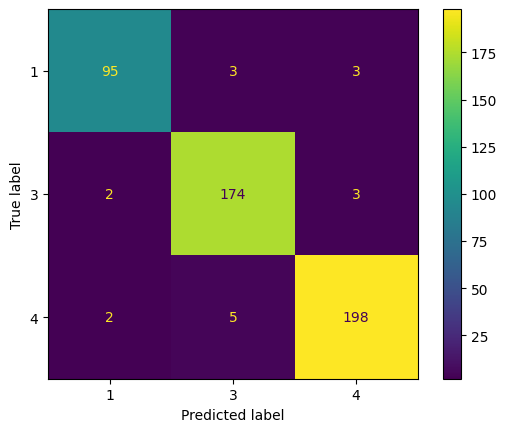

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             balanced_accuracy_score, accuracy_score)

# === Pipeline: TF-IDF -> Naive Bayes ===
pipe_nb = Pipeline(steps=[ 
    ('norm', TextNormalizer(remove_stopwords=True)),
    ('tfidf', TfidfVectorizer(
        lowercase=True,
        strip_accents='unicode',
        ngram_range=(1,1),
        min_df=2
    )),
    ('nb', MultinomialNB())
])

# === Grid MUY corto enfocado en F1-macro ===
param_grid_nb = {
    'tfidf__ngram_range': [(1,1), (1,2)],
    'tfidf__min_df': [1, 2],
    'nb__alpha': [0.1, 0.5, 1.0],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(pipe_nb, param_grid_nb, scoring='f1_macro', cv=cv, n_jobs=1, verbose=1)

grid.fit(X_train, y_train)

print("Mejores hiperparámetros encontrados:", grid.best_params_)
print("CV f1_macro:", round(grid.best_score_, 3))

best_nb = grid.best_estimator_

print("\n------------------ Métricas en test ------------------")
y_pred_nb = best_nb.predict(X_test)
print("accuracy:", round(accuracy_score(y_test, y_pred_nb), 3))
print("balanced_acc:", round(balanced_accuracy_score(y_test, y_pred_nb), 3))
print("f1_macro:", round(f1_score(y_test, y_pred_nb, average='macro'), 3))
print("f1_weighted:", round(f1_score(y_test, y_pred_nb, average='weighted'), 3))
print("\nReporte por clase:\n", classification_report(y_test, y_pred_nb, digits=3))

cm = confusion_matrix(y_test, y_pred_nb, labels=best_nb.classes_)
ConfusionMatrixDisplay(cm, display_labels=best_nb.classes_).plot(xticks_rotation=0)


### **Validación del modelo con los datos nuevos etapa 2**

#### **Validación de métricas en el mejor modelo con datos nuevos (sin técnicas de prompting)**

Como primer acercamiento, se obtendran las métricas para el conjunto de datos completo, por ahora no se utilizará ninguna de las particiones anteriormente realizadas.


------------------ Métricas en test ------------------
accuracy: 0.899
balanced_acc: 0.874
f1_macro: 0.887
f1_weighted: 0.896

Reporte por clase:
               precision    recall  f1-score   support

           1      1.000     0.714     0.833        21
           3      0.854     1.000     0.921        35
           4      0.907     0.907     0.907        43

    accuracy                          0.899        99
   macro avg      0.920     0.874     0.887        99
weighted avg      0.908     0.899     0.896        99



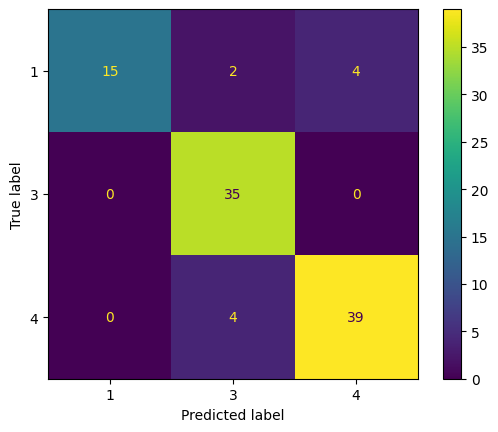

In [18]:
from sklearn.metrics import (
    classification_report, accuracy_score, balanced_accuracy_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

best_model = best_nb

print("\n------------------ Métricas en test ------------------")
y_pred_nb = best_model.predict(X_2)
print("accuracy:", round(accuracy_score(y_2, y_pred_nb), 3))
print("balanced_acc:", round(balanced_accuracy_score(y_2, y_pred_nb), 3))
print("f1_macro:", round(f1_score(y_2, y_pred_nb, average='macro'), 3))
print("f1_weighted:", round(f1_score(y_2, y_pred_nb, average='weighted'), 3))
print("\nReporte por clase:\n", classification_report(y_2, y_pred_nb, digits=3))

cm = confusion_matrix(y_2, y_pred_nb, labels=best_model.classes_)
ConfusionMatrixDisplay(cm, display_labels=best_model.classes_).plot(xticks_rotation=0)

Se obtuvó, para el segundo conjunto de datos completo, un F1-score macro de 0.88, el cual es menor al F1-score macro obtenido anteriormente (0.961).

Para mejorar las métricas, se realizarán las siguientes estrategías:

- Aumentación del segundo conjunto de datos mediante técnicas de prompting.
- Combinación entre el primer y segundo conjunto de datos con el objetivo de incrementar la cantidad de datos totales.
- Reentrenar el modelo con los datos nuevos (segundo conjunto aumentado + primer conjunto de datos).

### **Reentrenar mejor modelo con técnicas de prompting**

Primero se realizará la aumentación de datos para la totalidad del segundo conjunto de datos.

In [ ]:
# ============================
# 1) Imports y cliente OpenAI
# ============================
import os, json, math, re, random
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (classification_report, accuracy_score,
                             balanced_accuracy_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

from openai import OpenAI
# Asegúrate de tener la API key en el entorno
os.environ["OPENAI_API_KEY"] = ""  # <- poner api key aquí
client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))

# Utilidad: garantizar que X sea Serie de str y y sea Serie
def _as_series(x):
    s = pd.Series(x)
    s = s.fillna("").astype(str).reset_index(drop=True)
    return s

X_2_s = _as_series(X_2)
y_2_s = pd.Series(y_2)

# ============================
# 2) Detección de clase minoritaria
# ============================
vc = y_2_s.value_counts()
minor_label = vc.idxmin()
major_label = vc.idxmax()
print("Distribución y:\n", vc, "\nMinoritaria:", minor_label, "Mayorit.:", major_label)

# ============================
# 3) Función de llamada LLM (JSON mode)
# ============================
def llm_json(prompt: str, model: str = "gpt-4o-mini",
             temperature: float = 0.4, max_tokens: int = 1200) -> dict:
    """
    Llama al modelo y devuelve un dict (JSON). Intenta primero con response_format,
    y si tu SDK no lo soporta, cae a una llamada normal y parsea el JSON del texto.
    """
    sys = (
        "Eres un generador de datos sintéticos en ESPAÑOL para un clasificador de ODS. "
        "Devuelve EXCLUSIVAMENTE un JSON válido (sin texto adicional)."
    )
    # 1) Intento con response_format (si tu SDK lo soporta)
    try:
        resp = client.chat.completions.create(
            model=model,
            messages=[
                {"role": "system", "content": sys},
                {"role": "user", "content": prompt},
            ],
            temperature=temperature,
            max_tokens=max_tokens,
            response_format={"type": "json_object"},
        )
        text = resp.choices[0].message.content
    except TypeError:
        # 2) Fallback sin response_format
        resp = client.chat.completions.create(
            model=model,
            messages=[
                {"role": "system", "content": sys},
                {"role": "user", "content": prompt},
            ],
            temperature=temperature,
            max_tokens=max_tokens,
        )
        text = resp.choices[0].message.content

    # 3) Parseo robusto a dict
    try:
        return json.loads(text)
    except Exception:
        m = re.search(r"\{.*\}", text, flags=re.S)
        if m:
            try:
                return json.loads(m.group(0))
            except Exception:
                pass
        # Último recurso: convierte líneas a samples
        items = [ln.strip("-• \n\r\t") for ln in text.splitlines() if ln.strip()]
        return {"synthetic_samples": [{"texto": it} for it in items]}

# ============================
# 4) Construcción del prompt few-shot
# ============================
def construir_prompt(ejemplos:list, etiqueta_minoritaria, n_solicitados:int, otras_etiquetas:list):
    """
    ejemplos: lista de textos reales de la clase minoritaria (limpios).
    otras_etiquetas: etiquetas distintas a la minoritaria para evitar “contaminación semántica”.
    """
    # Limita a 10-12 ejemplos para que sea compacto
    ejemplos = ejemplos[:12]
    fewshot = [{"texto": t} for t in ejemplos]

    instrucciones = f"""
Eres un generador de textos sintéticos en ESPAÑOL para un clasificador de opiniones asociado a ODS.
Tu tarea: crear ejemplos REALISTAS de la clase {etiqueta_minoritaria} (minoritaria) que sean verosímiles,
variados y no copien literalmente los ejemplos de referencia.

Requisitos:
- Idioma: español natural y conciso (una o dos oraciones).
- Longitud: 12 a 50 palabras por ejemplo.
- Estilo: propio de la clase {etiqueta_minoritaria}. Evita términos característicos de clases {otras_etiquetas}.
- Variedad: usa sinónimos, ligeras variaciones de tono, y ocasionales faltas menores (realismo), sin caer en spam.
- Neutralidad de formato: texto plano, sin comillas de apertura/cierre.

Devuélveme EXCLUSIVAMENTE un objeto JSON con esta forma:
{{
  "synthetic_samples": [
      {{ "texto": "..." }},
      ...
  ]
}}
Dónde "synthetic_samples" contiene EXACTAMENTE {n_solicitados} ejemplos nuevos.
"""

    prompt = {
        "instrucciones": instrucciones,
        "ejemplos_reales_clase_minoritaria": fewshot
    }
    return json.dumps(prompt, ensure_ascii=False)

# ============================
# 5) Generación en lotes + filtros
# ============================
def normaliza_texto(t: str) -> str:
    t = t.strip()
    t = re.sub(r"\s+", " ", t)
    return t

def sintetizar_para_label(X_series, y_series, label, n_objetivo=300, batch=50):
    """
    Genera n_objetivo ejemplos de la clase 'label' en lotes 'batch'.
    Devuelve lista de textos sintéticos (filtrados y deduplicados).
    """
    # Semillas few-shot: toma ejemplos reales de esa clase
    # --- Semillas few-shot: toma ejemplos reales de esa clase (indexación POSICIONAL) ---
    X_series = _as_series(X_series).reset_index(drop=True)
    y_series = pd.Series(y_series).reset_index(drop=True)

    mask = (y_series.values == label)  # numpy bool array → fuerza alineación posicional
    n_disp = int(mask.sum())
    if n_disp == 0:
        raise ValueError(f"No hay ejemplos de la clase '{label}' en y_series.")

    n_sample = min(60, n_disp)
    ejemplos_reales = X_series[mask].sample(n_sample, random_state=42).tolist()

    otras = sorted([str(l) for l in y_series.unique() if l != label])

    sinteticos = []
    pendientes = n_objetivo
    while pendientes > 0:
        n_solic = min(batch, pendientes)

        prompt = construir_prompt(
            ejemplos=[normaliza_texto(x) for x in ejemplos_reales],
            etiqueta_minoritaria=label,
            n_solicitados=n_solic,
            otras_etiquetas=otras
        )
        try:
            data = llm_json(prompt, model="gpt-4o-mini", temperature=0.35, max_tokens=2000)
            nuevos = [normaliza_texto(d.get("texto","")) for d in data.get("synthetic_samples", [])]
        except Exception as e:
            print("⚠️  LLM error, salto de lote:", e)
            nuevos = []

        # Filtros básicos
        nuevos = [t for t in nuevos if 10 <= len(t.split()) <= 60]
        nuevos = [t for t in nuevos if len(t) >= 25]
        nuevos = [t for t in nuevos if t]

        sinteticos.extend(nuevos)
        pendientes -= n_solic

    # Deduplicación con el train real y dentro de los sintéticos
    set_train = set([normaliza_texto(t).lower() for t in X_series.tolist()])
    out = []
    seen = set()
    for t in sinteticos:
        key = t.lower()
        if key in seen:
            continue
        if key in set_train:
            continue
        seen.add(key)
        out.append(t)

    print(f"Sintéticos generados (tras filtros): {len(out)}")
    return out

# ============================
# 6) Estrategia: balancear hasta la mayoritaria
# ============================
minor_count = vc.loc[minor_label]
major_count = vc.loc[major_label]
to_generate = max(0, major_count - minor_count)
print(f"Objetivo de balanceo: generar {to_generate} textos para la clase {minor_label}.")

if to_generate > 0:
    synth_texts = sintetizar_para_label(X_2_s, y_2_s, minor_label, n_objetivo=to_generate, batch=40)
else:
    synth_texts = []

# Si generó “de más” por filtros flojos, recorta
synth_texts = synth_texts[:to_generate]

#normalización de los sintéticos (omitir porque se hará en el pipeline, se deja comentado para referencia)
# synth_series = pd.Series(synth_texts)
# synth_series_proc = normalize_texts_nltk(synth_series, remove_stopwords=True)

# ============================
# 7) Conjunto aumentado y reentrenamiento
# ============================
X_aug = pd.concat([X_2_s, pd.Series(synth_texts)], ignore_index=True)
y_aug = pd.concat([y_2_s, pd.Series([minor_label]*len(synth_texts))], ignore_index=True)

print("Tamaño conjunto original:", len(X_2_s), " | aumentado:", len(X_aug))
print("Distribución original:\n", y_2_s.value_counts())
print("Distribución aumentada:\n", y_aug.value_counts())

Distribución y:
 4    43
3    35
1    21
Name: count, dtype: int64 
Minoritaria: 1 Mayorit.: 4
Objetivo de balanceo: generar 22 textos para la clase 1.
Sintéticos generados (tras filtros): 22
Tamaño conjunto original: 99  | aumentado: 121
Distribución original:
 4    43
3    35
1    21
Name: count, dtype: int64
Distribución aumentada:
 1    43
4    43
3    35
Name: count, dtype: int64


Para que tenga sentido comparar los modelos (original y reentrenado) se debe reservar un conjunto de datos que no haya sido utilizado para entrenar ninguno de estos dos modelos. Para ello, reservaremos una pequeña partición del segundo conjunto de datos aumentado antes de combinar.

In [28]:
X_train_aug, X_test_aug, y_train_aug, y_test_aug = train_test_split(
    X_aug, y_aug, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_aug
)

Las particiones X_test_aug y y_test_aug serán reservadas para comparar ambos modelos después del reentrenamiento. Por otro lado, las particiones X_traing_aug y y_train_aug, serán combinadas con las particiones del conjunto de datos de la etapa 1. Con esto nos aseguramos de no incorporar ningún sesgo al momento de comparar.

In [29]:
# Combinar Datos etapa 1 con datos etapa 2 aumentados
X_final = pd.concat([X, X_train_aug], ignore_index=True)
y_final = pd.concat([pd.Series(y), y_train_aug], ignore_index=True)

# Tamaño final
print("Tamaño final combinado:", len(X_final))
print("Distribución final combinada:\n", y_final.value_counts())

Tamaño final combinado: 2520
Distribución final combinada:
 4    1059
3     922
1     539
Name: count, dtype: int64


Dado que todavía hay un desbalance, se volverá a realizar una aumentación de la clase minoritaria para este conjunto de datos combinado.

In [30]:
X_final_s = _as_series(X_final)
y_final_s = pd.Series(y_final)

# ============================
# Detección de clase minoritaria
# ============================
vc = y_final_s.value_counts()
minor_label = vc.idxmin()
major_label = vc.idxmax()
print("Distribución y:\n", vc, "\nMinoritaria:", minor_label, "Mayorit.:", major_label)

# ============================
minor_count = vc.loc[minor_label]
major_count = vc.loc[major_label]
to_generate = max(0, major_count - minor_count)
print(f"Objetivo de balanceo: generar {to_generate} textos para la clase {minor_label}.")

if to_generate > 0:
    synth_texts = sintetizar_para_label(X_final_s, y_final_s, minor_label, n_objetivo=to_generate, batch=40)
else:
    synth_texts = []

# Si generó “de más” por filtros flojos, recorta
synth_texts = synth_texts[:to_generate]

#normalización de los sintéticos
synth_series = pd.Series(synth_texts)
synth_series_proc = normalize_texts_nltk(synth_series, remove_stopwords=True)

# ============================
# Conjunto aumentado y reentrenamiento
# ============================
X_final = pd.concat([X_final_s, pd.Series(synth_series_proc)], ignore_index=True)
y_final = pd.concat([y_final_s, pd.Series([minor_label]*len(synth_series_proc))], ignore_index=True)

print("Tamaño conjunto original:", len(X_final_s), " | aumentado:", len(X_final))
print("Distribución original:\n", y_final_s.value_counts())
print("Distribución aumentada:\n", y_final.value_counts())

Distribución y:
 4    1059
3     922
1     539
Name: count, dtype: int64 
Minoritaria: 1 Mayorit.: 4
Objetivo de balanceo: generar 520 textos para la clase 1.
Sintéticos generados (tras filtros): 569
Tamaño conjunto original: 2520  | aumentado: 3040
Distribución original:
 4    1059
3     922
1     539
Name: count, dtype: int64
Distribución aumentada:
 4    1059
1    1059
3     922
Name: count, dtype: int64


Ahora si pasamos a el reentrenamiento del modelo con este conjunto de datos. A su vez, se calcularán las métricas para ambos modelos (original y reentrenado) con la partición que ya habiamos reservado anteriormente y cuyas distribuciones son las siguientes.

In [31]:
print("Tamaño partición de test:", len(X_test_aug))
print("Distribución partición de test:\n", y_test_aug.value_counts())

Tamaño partición de test: 25
Distribución partición de test:
 4    9
1    9
3    7
Name: count, dtype: int64



------------------ Métricas en test final combinado ------------------
accuracy: 0.96
balanced_acc: 0.963
f1_macro: 0.958
f1_weighted: 0.96

Reporte por clase:
               precision    recall  f1-score   support

           1      1.000     1.000     1.000         9
           3      0.875     1.000     0.933         7
           4      1.000     0.889     0.941         9

    accuracy                          0.960        25
   macro avg      0.958     0.963     0.958        25
weighted avg      0.965     0.960     0.960        25



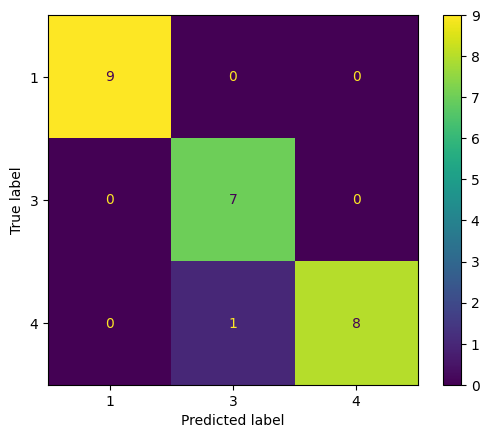

In [32]:
# Clonamos y re-entrenamos Naive Bayes (pipeline)
best_nb_aug = clone(best_nb)
best_nb_aug.fit(X_final, y_final)

print("\n------------------ Métricas en test final combinado ------------------")
y_pred_nb_final = best_nb_aug.predict(X_test_aug)
print("accuracy:", round(accuracy_score(y_test_aug, y_pred_nb_final), 3))
print("balanced_acc:", round(balanced_accuracy_score(y_test_aug, y_pred_nb_final), 3))
print("f1_macro:", round(f1_score(y_test_aug, y_pred_nb_final,    average='macro'), 3))
print("f1_weighted:", round(f1_score(y_test_aug, y_pred_nb_final, average='weighted'), 3))
print("\nReporte por clase:\n", classification_report(y_test_aug, y_pred_nb_final, digits=3))
cm = confusion_matrix(y_test_aug, y_pred_nb_final, labels=best_nb_aug.classes_)
ConfusionMatrixDisplay(cm, display_labels=best_nb_aug.classes_).plot(xticks_rotation=0)



------------------ Métricas en test (modelo anterior) ------------------
accuracy: 0.8
balanced_acc: 0.815
f1_macro: 0.796
f1_weighted: 0.79

Reporte por clase:
               precision    recall  f1-score   support

           1      1.000     0.556     0.714         9
           3      0.778     1.000     0.875         7
           4      0.727     0.889     0.800         9

    accuracy                          0.800        25
   macro avg      0.835     0.815     0.796        25
weighted avg      0.840     0.800     0.790        25



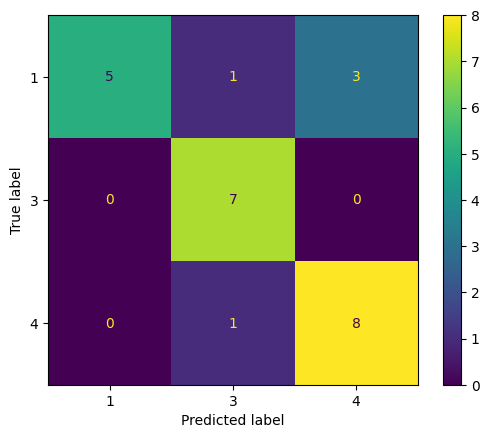

In [33]:
best_model = best_nb

print("\n------------------ Métricas en test (modelo anterior) ------------------")
y_pred_nb = best_model.predict(X_test_aug)
print("accuracy:", round(accuracy_score(y_test_aug, y_pred_nb), 3))
print("balanced_acc:", round(balanced_accuracy_score(y_test_aug, y_pred_nb), 3))
print("f1_macro:", round(f1_score(y_test_aug, y_pred_nb, average='macro'), 3))
print("f1_weighted:", round(f1_score(y_test_aug, y_pred_nb, average='weighted'), 3))
print("\nReporte por clase:\n", classification_report(y_test_aug, y_pred_nb, digits=3))

cm = confusion_matrix(y_test_aug, y_pred_nb, labels=best_model.classes_)
ConfusionMatrixDisplay(cm, display_labels=best_model.classes_).plot(xticks_rotation=0)

### **Tabla de comparación**

In [34]:
%pip install tabulate
import numpy as np, pandas as pd
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score, f1_score

def _eval_model(model, X, y, nombre):
    y_pred = model.predict(pd.Series(X).astype(str))
    rep = classification_report(y, y_pred, output_dict=True, zero_division=0)
    labels = sorted(np.unique(y))

    fila = {
        "Modelo": nombre,
        "n_test": len(y),
        "accuracy": accuracy_score(y, y_pred),
        "balanced_acc": balanced_accuracy_score(y, y_pred),
        "f1_macro": f1_score(y, y_pred, average="macro"),
        "f1_weighted": f1_score(y, y_pred, average="weighted"),
    }
    # métricas por clase
    for c in labels:
        cstr = str(c)
        fila[f"precision_{c}"] = rep[cstr]["precision"]
        fila[f"recall_{c}"]    = rep[cstr]["recall"]
        fila[f"f1_{c}"]        = rep[cstr]["f1-score"]
    return fila

# Evalúa ambos modelos sobre el MISMO test reservado
row_orig = _eval_model(best_model,     X_test_aug, y_test_aug, "NB original")
row_aug  = _eval_model(best_nb_aug, X_test_aug, y_test_aug, "NB reentrenado")

# Tabla base
tabla = pd.DataFrame([row_orig, row_aug]).round(3)

# Reordena columnas para que se vean primero las globales
label_cols = []
for c in sorted(np.unique(y_test_aug)):
    label_cols += [f"precision_{c}", f"recall_{c}", f"f1_{c}"]

cols = ["Modelo","n_test","accuracy","balanced_acc","f1_macro","f1_weighted"] + label_cols
tabla = tabla[cols]

# Fila de diferencias (reentrenado - original)
tabla_num = tabla.set_index("Modelo").apply(pd.to_numeric, errors="ignore")
delta = (tabla_num.loc["NB reentrenado"] - tabla_num.loc["NB original"]).to_frame().T
delta.index = ["Δ (reentrenado - original)"]
tabla_final = pd.concat([tabla_num, delta]).round(3)

# Como markdown
print(tabla_final.to_markdown())


Note: you may need to restart the kernel to use updated packages.
|                            |   n_test |   accuracy |   balanced_acc |   f1_macro |   f1_weighted |   precision_1 |   recall_1 |   f1_1 |   precision_3 |   recall_3 |   f1_3 |   precision_4 |   recall_4 |   f1_4 |
|:---------------------------|---------:|-----------:|---------------:|-----------:|--------------:|--------------:|-----------:|-------:|--------------:|-----------:|-------:|--------------:|-----------:|-------:|
| NB original                |       25 |       0.8  |          0.815 |      0.796 |          0.79 |             1 |      0.556 |  0.714 |         0.778 |          1 |  0.875 |         0.727 |      0.889 |  0.8   |
| NB reentrenado             |       25 |       0.96 |          0.963 |      0.958 |          0.96 |             1 |      1     |  1     |         0.875 |          1 |  0.933 |         1     |      0.889 |  0.941 |
| Δ (reentrenado - original) |        0 |       0.16 |          0.148 |   

C:\Users\Juan\AppData\Local\Temp\ipykernel_25092\1109670461.py:42: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  tabla_num = tabla.set_index("Modelo").apply(pd.to_numeric, errors="ignore")


### **Exportación del modelo reentrenado utilizando la libreria Joblib**

Para proceder con la sección 2, primero deberemos exportar el modelo de aprendizaje automático reentrenado a un archivo .joblib. Para ello construiremos el pipeline correspondiente. En este ya se incluye la automatización de procesos asociados a preprocesamiento de texto.

In [44]:
# --- Guardar ---
import os, json, joblib, sklearn, pandas as pd
from datetime import datetime

ARTIFACTS_DIR = "artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
MODEL_PATH = f"{ARTIFACTS_DIR}/nb_pipeline_v2_{stamp}.joblib"
META_PATH  = f"{ARTIFACTS_DIR}/model_card_{stamp}.json"

# best_nb_aug viene del entrenamiento
joblib.dump(best_nb_aug, MODEL_PATH)

meta = {
    "model_path": MODEL_PATH,
    "library": "scikit-learn",
    "sklearn_version": sklearn.__version__,
    "trained_on": "datos etapa1 + etapa2 (augmentados)",
    "expects_preprocessed_text": True,  # <-- importante para la API
    "labels": sorted(pd.Series(y_final).unique().tolist()),
}
with open(META_PATH, "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

print("Guardado:", MODEL_PATH)
print("Card    :", META_PATH)


Guardado: artifacts/nb_pipeline_v2_20251013_114435.joblib
Card    : artifacts/model_card_20251013_114435.json


### Persistencia del modelo 

Para asegurar la persistencia del modelo, hemos decidido crear un histórico que ira guardando los datos de entrenamiento utilizados para futuros reentrenamientos desde la aplicación en secciones posteriores. La celda de código siguiente dejará el histórico definido con el conjunto de datos de entrenamiento final usado hasta este punto.

In [45]:
import pandas as pd
from pathlib import Path

# Usa EXACTAMENTE los textos/labels con los que fitteaste tu pipeline final.
# Si tu pipeline ya incluye TextNormalizer, aquí deben ser los textos CRUDOS.
# Ajusta X_final / y_final al nombre que tengas en tu entorno.
df_seed = pd.DataFrame({
    "texto": pd.Series(X_final).astype(str).values,
    "label": pd.Series(y_final).values
})

artifacts = Path("artifacts")
artifacts.mkdir(parents=True, exist_ok=True)
df_seed.to_csv(artifacts / "train_store.csv", index=False, encoding="utf-8")

print("Semilla de histórico creada en artifacts/train_store.csv:", len(df_seed), "filas")


Semilla de histórico creada en artifacts/train_store.csv: 3040 filas


A su vez, vamos a persistir el conjunto que usamos para calcular las métricas, esto para ir calculando las métricas por cada reentrenamiento desde la aplicación en secciones posteriores.

In [46]:
import pandas as pd
from pathlib import Path

artifacts = Path("artifacts")
artifacts.mkdir(parents=True, exist_ok=True)

df_eval = pd.DataFrame({
    "texto": pd.Series(X_test_aug).astype(str).values,
    "label": pd.Series(y_test_aug).values
})
df_eval.to_csv(artifacts / "eval_holdout.csv", index=False, encoding="utf-8")

print("Holdout persistente creado:", len(df_eval), "filas")


Holdout persistente creado: 25 filas


### Prueba de uso

In [41]:
import joblib, pandas as pd

pipe = joblib.load(MODEL_PATH)

def preprocess_for_api(texts):
    s = pd.Series(texts).fillna("").astype(str)
    return normalize_texts_nltk(s, remove_stopwords=True)  # misma normalización que en entrenamiento

ejemplo = ["Texto crudo del usuario…"]
X_infer = preprocess_for_api(ejemplo)
pred = pipe.predict(X_infer)
proba = pipe.predict_proba(X_infer) if hasattr(pipe, "predict_proba") else None

print(pred, proba)


[3] [[0.09483179 0.46033201 0.4448362 ]]


## **Sección 2: Proceso de automatización del proceso de preparación de datos, construcción del modelo, persistencia del modelo y acceso por medio de API**

Con el pipeline exportado en un archivo .joblib, se procedera con la construcción del api. Esto se realizará en los archivos .py adjuntos correspondientes.